# 3. Monte Carlo Estimation

*Part 3 of **Stochastic Modelling and Monte Carlo Methods for Financial Markets**.*

Monte Carlo estimates an expectation by averaging simulated samples. For a random variable $X$ and a function $f$, the target is $\theta = \mathbb{E}[f(X)]$ and the estimator is

$$
\hat{\theta}_N = \frac{1}{N} \sum_{i=1}^{N} f(X_i), \qquad X_i \overset{\text{i.i.d.}}{\sim} X.
$$

Two classical results describe its behaviour:

- **Law of large numbers**: $\hat{\theta}_N \to \theta$ as $N \to \infty$, and $\hat\theta_N$ is unbiased.
- **Central limit theorem**: $\hat{\theta}_N \approx \mathcal{N}\!\left(\theta,\; \sigma_f^2 / N\right)$ with $\sigma_f^2 = \operatorname{Var}(f(X))$.

So the **standard error** is

$$
\operatorname{SE}(\hat\theta_N) = \frac{\sigma_f}{\sqrt{N}} \approx \frac{s_f}{\sqrt{N}},
$$

and an approximate 95% confidence interval is $\hat\theta_N \pm 1.96\,\operatorname{SE}$. The error shrinks at rate $O(1/\sqrt{N})$ regardless of the dimension of the problem.

This notebook applies these ideas to the GBM model from Notebook 2. Everything here is under the **real-world drift $\mu$**; the switch to pricing under the risk-neutral drift $r$ comes in Notebook 4.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Make the project's src/ package importable when running from notebooks/
sys.path.insert(0, str(Path.cwd().parent / "src"))

from stochmc import (
    european_payoff,
    gbm_expected_price,
    gbm_terminal_prices,
    gbm_median_price,
    simulate_gbm_paths,
    simulate_gbm_terminal,
    summarise_samples,
)

SEED = 42
rng = np.random.default_rng(SEED)

In [2]:
initial_price = 100
annual_drift = 0.08
annual_volatility = 0.20
time_horizon = 1
strike_price = 110

## 3.1 Simulating terminal distributions

Many quantities depend only on the terminal price $S_T$. Because GBM has an explicit solution, $S_T$ can be drawn in **one step**,

$$
S_T = S_0 \exp\!\left[\left(\mu - \tfrac12\sigma^2\right)T + \sigma\sqrt{T}\,Z\right],
$$

with no time grid. This is exact and much cheaper than simulating full paths.

The two approaches agree exactly: a 252-step path's endpoint is the one-step formula applied to $Z = \tfrac{1}{\sqrt{252}}\sum_i Z_i$, which is again standard normal.

In [3]:
n_simulations = 100_000

terminal_prices = simulate_gbm_terminal(
    initial_price=initial_price,
    drift=annual_drift,
    volatility=annual_volatility,
    time_horizon=time_horizon,
    n_paths=n_simulations,
    rng=rng
)

path_seed = 7
n_path_steps = 252

_, path_prices = simulate_gbm_paths(
    initial_price=initial_price,
    drift=annual_drift,
    volatility=annual_volatility,
    time_horizon=time_horizon,
    n_steps=n_path_steps,
    n_paths=20_000,
    rng=np.random.default_rng(path_seed)
)

# Regenerate the same per-step shocks and collapse them into one N(0, 1) draw per path
same_shocks = np.random.default_rng(path_seed).standard_normal((20_000, n_path_steps))
collapsed_shocks = same_shocks.sum(axis=1) / np.sqrt(n_path_steps)

one_step_from_same_shocks = gbm_terminal_prices(
    initial_price, annual_drift, annual_volatility, time_horizon, collapsed_shocks
)

max_path_vs_one_step_difference = np.max(np.abs(path_prices[:, -1] - one_step_from_same_shocks))
print(f"Max |path endpoint - one-step price| using the same shocks: {max_path_vs_one_step_difference:.2e}")

# Compare quantiles of both samples with the exact lognormal distribution
quantile_levels = [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
lognormal_terminal = stats.lognorm(
    s=annual_volatility * np.sqrt(time_horizon),
    scale=gbm_median_price(initial_price, annual_drift, annual_volatility, time_horizon)
)

pd.DataFrame({
    "one_step_simulation": np.quantile(terminal_prices, quantile_levels),
    "path_endpoint": np.quantile(path_prices[:, -1], quantile_levels),
    "exact_lognormal": lognormal_terminal.ppf(quantile_levels),
}, index=pd.Index(quantile_levels, name="quantile"))

Max |path endpoint - one-step price| using the same shocks: 1.71e-13


,one_step_simulation,path_endpoint,exact_lognormal
quantile,,,
0.01,66.451203,66.683750,66.679703
0.05,76.210624,76.600051,76.416563
0.25,92.709116,92.857088,92.783817
0.50,105.992617,106.216255,106.183655
0.75,121.401556,121.401355,121.518697
0.95,147.594536,147.032396,147.546136
0.99,169.663621,168.325676,169.091461


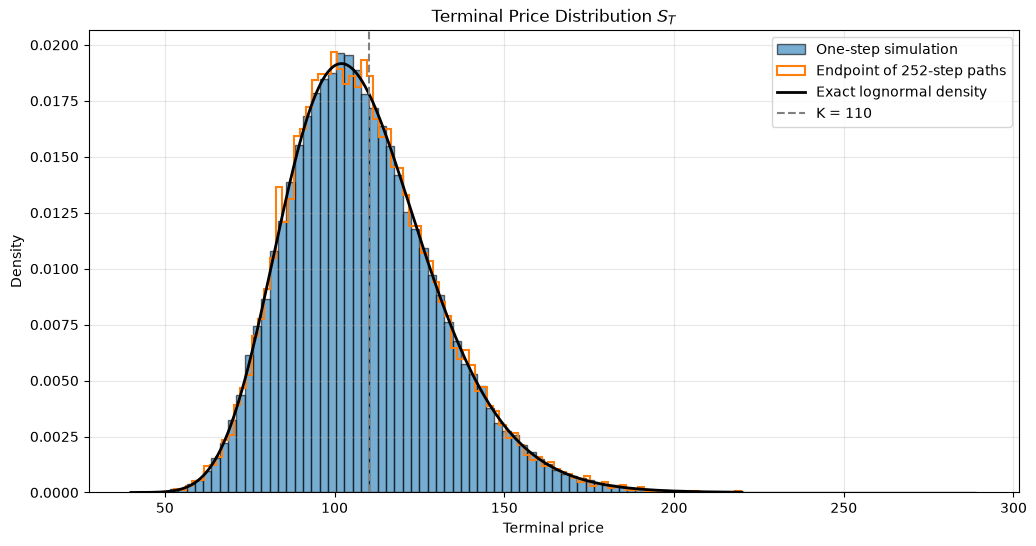

In [4]:
price_grid = np.linspace(40, 220, 500)

fig, ax = plt.subplots(figsize=(12, 6))

ax.hist(
    terminal_prices,
    bins=100,
    density=True,
    alpha=0.6,
    edgecolor="black",
    label="One-step simulation"
)

ax.hist(
    path_prices[:, -1],
    bins=100,
    density=True,
    histtype="step",
    linewidth=1.5,
    label="Endpoint of 252-step paths"
)

ax.plot(price_grid, lognormal_terminal.pdf(price_grid), "k", linewidth=2, label="Exact lognormal density")
ax.axvline(strike_price, linestyle="--", color="grey", label=f"K = {strike_price}")

ax.set_title("Terminal Price Distribution $S_T$")
ax.set_xlabel("Terminal price")
ax.set_ylabel("Density")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

Both samples match the exact lognormal density, so for problems that only need $S_T$, one-step simulation is used from here on.

## 3.2 Estimating expected payoffs

Three expectations of $S_T$ are estimated below. Each has a closed form under GBM, so the estimates can be checked:

| Quantity | $f(S_T)$ | Closed form |
|---|---|---|
| Expected price | $S_T$ | $S_0 e^{\mu T}$ |
| Probability of finishing above $K$ | $\mathbf{1}\{S_T > K\}$ | $\Phi(d_2)$ |
| Expected call payoff | $\max(S_T - K, 0)$ | $S_0 e^{\mu T}\Phi(d_1) - K\,\Phi(d_2)$ |

where $d_{1,2} = \dfrac{\ln(S_0/K) + (\mu \pm \tfrac12\sigma^2)T}{\sigma\sqrt{T}}$.

The last row is the *undiscounted* Black–Scholes formula with $r$ replaced by $\mu$. It is the expected payoff under the real-world measure, **not** an option price.

In [5]:
sqrt_t = np.sqrt(time_horizon)
d1 = (
    np.log(initial_price / strike_price)
    + (annual_drift + 0.5 * annual_volatility**2) * time_horizon
) / (annual_volatility * sqrt_t)
d2 = d1 - annual_volatility * sqrt_t

exact_values = {
    "E[S_T]": gbm_expected_price(initial_price, annual_drift, time_horizon),
    "P(S_T > K)": stats.norm.cdf(d2),
    "E[max(S_T - K, 0)]": (
        initial_price * np.exp(annual_drift * time_horizon) * stats.norm.cdf(d1)
        - strike_price * stats.norm.cdf(d2)
    ),
}

payoff_samples = {
    "E[S_T]": terminal_prices,
    "P(S_T > K)": (terminal_prices > strike_price).astype(float),
    "E[max(S_T - K, 0)]": european_payoff(terminal_prices, strike_price, "call"),
}

estimate_rows = []

for name, samples in payoff_samples.items():
    result = summarise_samples(samples)
    low, high = result.confidence_interval

    estimate_rows.append({
        "quantity": name,
        "mc_estimate": result.estimate,
        "standard_error": result.standard_error,
        "ci_95_low": low,
        "ci_95_high": high,
        "exact_value": exact_values[name],
        "exact_inside_ci": result.contains(exact_values[name])
    })

estimates = pd.DataFrame(estimate_rows).set_index("quantity")
estimates

,mc_estimate,standard_error,ci_95_low,ci_95_high,exact_value,exact_inside_ci
quantity,,,,,,
E[S_T],108.254263,0.069486,108.118073,108.390454,108.328707,True
P(S_T > K),0.427000,0.001564,0.423934,0.430066,0.429931,True
"E[max(S_T - K, 0)]",7.875451,0.043576,7.790043,7.960859,7.885294,True


Each estimate comes with its own error bar. The standard error is computed from the same samples as the estimate, so no knowledge of the true answer is needed. This is what makes Monte Carlo usable when no closed form exists.

## 3.3 Sampling error

$\hat\theta_N$ is itself a random variable: rerunning the simulation with fresh random numbers gives a different answer. To see its distribution, the whole experiment is repeated many times at a fixed $N$.

In [6]:
def repeated_estimates(f, n_samples, n_repetitions):
    """Run the Monte Carlo experiment n_repetitions times with n_samples each."""
    estimates = np.empty(n_repetitions)

    for i in range(n_repetitions):
        samples = simulate_gbm_terminal(
            initial_price, annual_drift, annual_volatility, time_horizon, n_samples, rng
        )
        estimates[i] = f(samples).mean()

    return estimates


def expected_call_payoff(samples):
    return european_payoff(samples, strike_price, "call")


true_expected_payoff = exact_values["E[max(S_T - K, 0)]"]

# Payoff standard deviation sigma_f, estimated from the large sample above
payoff_std = payoff_samples["E[max(S_T - K, 0)]"].std(ddof=1)

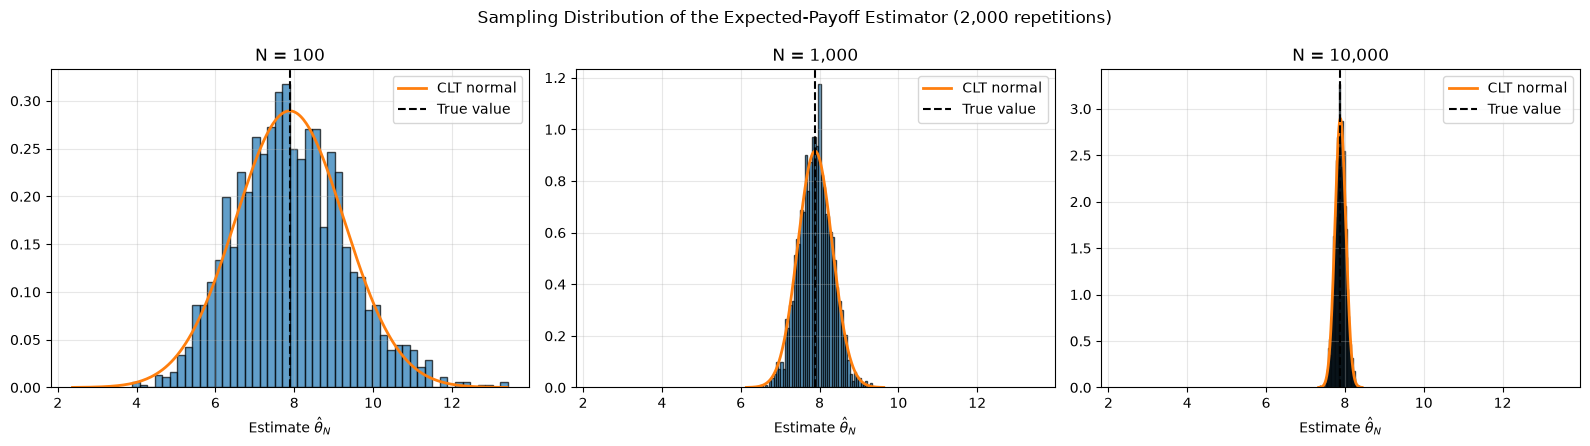

,mean_of_estimates,true_value,empirical_std_of_estimates,theoretical_se (sigma_f / sqrt N)
N,,,,
100,7.904423,7.885294,1.393407,1.378003
1000,7.893450,7.885294,0.417641,0.435763
10000,7.882070,7.885294,0.135680,0.137800


In [7]:
sample_sizes_to_compare = [100, 1_000, 10_000]
n_repetitions = 2_000

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True)
sampling_rows = []

for ax, n_samples in zip(axes, sample_sizes_to_compare):
    estimates_at_n = repeated_estimates(expected_call_payoff, n_samples, n_repetitions)
    theoretical_se = payoff_std / np.sqrt(n_samples)

    ax.hist(estimates_at_n, bins=50, density=True, alpha=0.7, edgecolor="black")

    grid = np.linspace(true_expected_payoff - 4 * theoretical_se, true_expected_payoff + 4 * theoretical_se, 300)
    ax.plot(grid, stats.norm.pdf(grid, true_expected_payoff, theoretical_se), linewidth=2, label="CLT normal")
    ax.axvline(true_expected_payoff, color="black", linestyle="--", label="True value")

    ax.set_title(f"N = {n_samples:,}")
    ax.set_xlabel(r"Estimate $\hat\theta_N$")
    ax.legend()
    ax.grid(alpha=0.3)

    sampling_rows.append({
        "N": n_samples,
        "mean_of_estimates": estimates_at_n.mean(),
        "true_value": true_expected_payoff,
        "empirical_std_of_estimates": estimates_at_n.std(ddof=1),
        "theoretical_se (sigma_f / sqrt N)": theoretical_se
    })

fig.suptitle(f"Sampling Distribution of the Expected-Payoff Estimator ({n_repetitions:,} repetitions)")
plt.tight_layout()
plt.show()

pd.DataFrame(sampling_rows).set_index("N")

The pictures confirm three things:

- the estimator is **unbiased**: its distribution is centred on the true value for every $N$;
- it is approximately **normal**, even though the payoff itself is very skewed (most payoffs are zero);
- its spread matches $\sigma_f/\sqrt{N}$ and shrinks by a factor of $\sqrt{10} \approx 3.16$ each time $N$ grows tenfold.

## 3.4 Convergence at rate $O(1/\sqrt{N})$

First a single long run. The running estimate $\hat\theta_n$ settles towards the true value inside a funnel of width $\pm 1.96\,s_f/\sqrt{n}$.

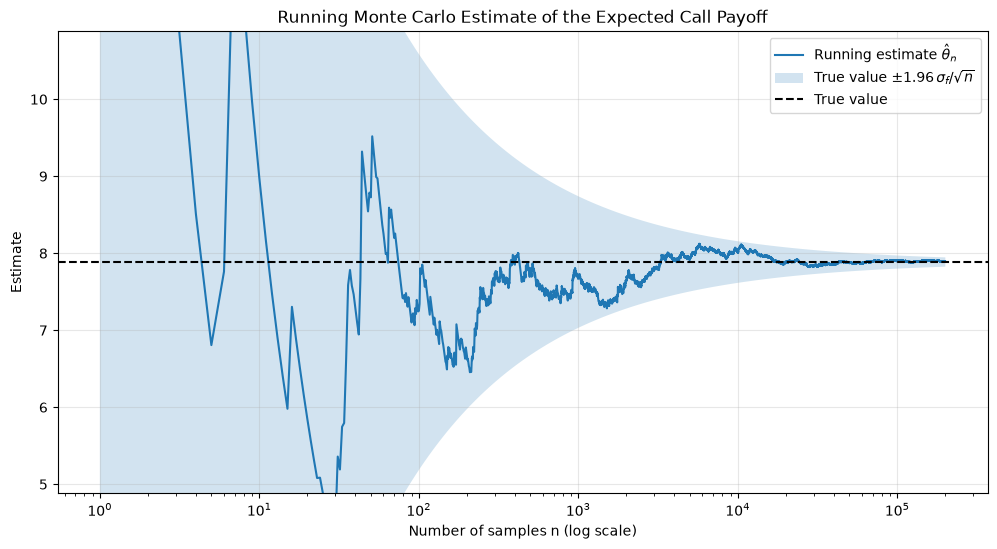

In [8]:
long_run_size = 200_000

long_run_payoffs = expected_call_payoff(
    simulate_gbm_terminal(initial_price, annual_drift, annual_volatility, time_horizon, long_run_size, rng)
)

n_values = np.arange(1, long_run_size + 1)
running_mean = np.cumsum(long_run_payoffs) / n_values
running_half_width = 1.96 * payoff_std / np.sqrt(n_values)

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(n_values, running_mean, linewidth=1.5, label=r"Running estimate $\hat\theta_n$")
ax.fill_between(
    n_values,
    true_expected_payoff - running_half_width,
    true_expected_payoff + running_half_width,
    alpha=0.2,
    label=r"True value $\pm 1.96\,\sigma_f/\sqrt{n}$"
)
ax.axhline(true_expected_payoff, color="black", linestyle="--", label="True value")

ax.set_xscale("log")
ax.set_ylim(true_expected_payoff - 3, true_expected_payoff + 3)
ax.set_title("Running Monte Carlo Estimate of the Expected Call Payoff")
ax.set_xlabel("Number of samples n (log scale)")
ax.set_ylabel("Estimate")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

To measure the rate, the root-mean-squared error (RMSE) of $\hat\theta_N$ over many repetitions is plotted against $N$ on log-log axes. If the error is $C N^{-1/2}$ the points lie on a line of slope $-\tfrac12$.

In [9]:
sample_sizes = np.array([100, 300, 1_000, 3_000, 10_000, 30_000, 100_000])
n_repetitions = 300

rmse_values = []

for n_samples in sample_sizes:
    estimates_at_n = repeated_estimates(expected_call_payoff, n_samples, n_repetitions)
    rmse_values.append(np.sqrt(np.mean((estimates_at_n - true_expected_payoff) ** 2)))

rmse_values = np.array(rmse_values)

# Fit log(RMSE) = log(C) + slope * log(N)
slope, intercept = np.polyfit(np.log(sample_sizes), np.log(rmse_values), 1)

pd.DataFrame({
    "N": sample_sizes,
    "rmse": rmse_values,
    "theoretical_se": payoff_std / np.sqrt(sample_sizes),
}).set_index("N")

,rmse,theoretical_se
N,,
100,1.427437,1.378003
300,0.769156,0.795590
1000,0.442563,0.435763
3000,0.251103,0.251588
10000,0.146481,0.137800
30000,0.077983,0.079559
100000,0.042123,0.043576


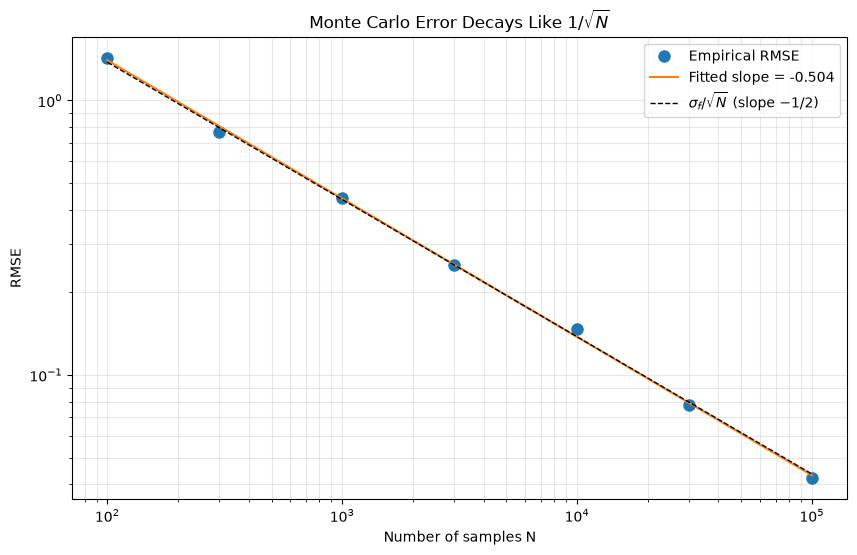

In [10]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.loglog(sample_sizes, rmse_values, "o", markersize=8, label="Empirical RMSE")
ax.loglog(
    sample_sizes,
    np.exp(intercept) * sample_sizes**slope,
    linewidth=1.5,
    label=f"Fitted slope = {slope:.3f}"
)
ax.loglog(
    sample_sizes,
    payoff_std / np.sqrt(sample_sizes),
    "k--",
    linewidth=1,
    label=r"$\sigma_f / \sqrt{N}$ (slope $-1/2$)"
)

ax.set_title("Monte Carlo Error Decays Like $1/\\sqrt{N}$")
ax.set_xlabel("Number of samples N")
ax.set_ylabel("RMSE")
ax.legend()
ax.grid(alpha=0.3, which="both")

plt.show()

In [11]:
assert np.all(terminal_prices > 0)
assert max_path_vs_one_step_difference < 1e-8
assert estimates["exact_inside_ci"].sum() >= 2
assert abs(slope + 0.5) < 0.1

print("Monte Carlo estimation checks passed.")

Monte Carlo estimation checks passed.


## Conclusions

- Monte Carlo replaces an expectation with a sample average. The estimator is unbiased, and by the CLT it is approximately normal.
- Its accuracy is measured by the standard error $s_f/\sqrt{N}$, computed from the samples themselves, which gives a confidence interval without knowing the answer.
- The error decays like $O(1/\sqrt{N})$: each extra digit of accuracy costs **100×** more samples.
- The constant in front of the rate is $\sigma_f$, the standard deviation of the payoff. Reducing $\sigma_f$ while keeping the estimator unbiased is the aim of **variance reduction** (Notebook 6).

So far all expectations were taken under the real-world drift $\mu$. An expected payoff is not a price. Notebook 4 introduces the risk-neutral measure and discounting to turn this machinery into an option pricer.